In [24]:
!wget https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Influenza/geography_types/Nation/geographies/England/metrics/influenza_healthcare_ICUHDUadmissionRateByWeek

--2026-10-23 11:22:12--  https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Influenza/geography_types/Nation/geographies/England/metrics/influenza_healthcare_ICUHDUadmissionRateByWeek
Resolving api.ukhsa-dashboard.data.gov.uk (api.ukhsa-dashboard.data.gov.uk)... 108.138.217.42, 108.138.217.92, 108.138.217.88, ...
Connecting to api.ukhsa-dashboard.data.gov.uk (api.ukhsa-dashboard.data.gov.uk)|108.138.217.42|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2222 (2.2K) [application/json]
Saving to: ‘influenza_healthcare_ICUHDUadmissionRateByWeek.2’

influenza_healthcar 100%[===================>]   2.17K  --.-KB/s    in 0s      

2026-10-23 11:22:12 (861 MB/s) - ‘influenza_healthcare_ICUHDUadmissionRateByWeek.2’ saved [2222/2222]



In [25]:
!cat influenza_healthcare_ICUHDUadmissionRateByWeek

{"count":2950,"next":"https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Influenza/geography_types/Nation/geographies/England/metrics/influenza_healthcare_ICUHDUadmissionRateByWeek?page=2","previous":null,"results":[{"theme":"infectious_disease","sub_theme":"respiratory","topic":"Influenza","geography_type":"Nation","geography":"England","geography_code":"E92000001","metric":"influenza_healthcare_ICUHDUadmissionRateByWeek","metric_group":"healthcare","stratum":"default","sex":"all","age":"all","year":2015,"month":6,"epiweek":27,"date":"2015-06-29","metric_value":0.0,"in_reporting_delay_period":false},{"theme":"infectious_disease","sub_theme":"respiratory","topic":"Influenza","geography_type":"Nation","geography":"England","geography_code":"E92000001","metric":"influenza_healthcare_ICUHDUadmissionRateByWeek","metric_group":"healthcare","stratum":"default","sex":"all","age":"all","year":2015,"month":7,"epiweek":28,"date":"2015-07-06","metric_v

In [3]:
import requests

requests.get("https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Influenza/geography_types/Nation/geographies/England/metrics/influenza_healthcare_ICUHDUadmissionRateByWeek", params={'year': 2025, 'page': 2}).json()

{'count': 468,
 'next': 'https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Influenza/geography_types/Nation/geographies/England/metrics/influenza_healthcare_ICUHDUadmissionRateByWeek?page=3&year=2025',
 'previous': 'https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Influenza/geography_types/Nation/geographies/England/metrics/influenza_healthcare_ICUHDUadmissionRateByWeek?year=2025',
 'results': [{'theme': 'infectious_disease',
   'sub_theme': 'respiratory',
   'topic': 'Influenza',
   'geography_type': 'Nation',
   'geography': 'England',
   'geography_code': 'E92000001',
   'metric': 'influenza_healthcare_ICUHDUadmissionRateByWeek',
   'metric_group': 'healthcare',
   'stratum': 'default',
   'sex': 'all',
   'age': '15-44',
   'year': 2025,
   'month': 1,
   'epiweek': 2,
   'date': '2025-01-06',
   'metric_value': 0.18,
   'in_reporting_delay_period': False},
  {'theme': 'infectious_disease',

In [26]:
import requests
import time

class APIwrapper:
    # class variables shared among all instances
    _access_point="https://api.ukhsa-dashboard.data.gov.uk"
    _last_access=0.0 # time of last api access
    
    def __init__(self, theme, sub_theme, topic, geography_type, geography, metric):
        """ Init the APIwrapper object, constructing the endpoint from the structure
        parameters """
        # build the path with all the required structure parameters. You do not need to edit this line,
        # parameters will be replaced by the actual values when you instantiate an object of the class!
        url_path=(f"/themes/{theme}/sub_themes/{sub_theme}/topics/{topic}/geography_types/" +
                  f"{geography_type}/geographies/{geography}/metrics/{metric}")
        # our starting API endpoint
        self._start_url=APIwrapper._access_point+url_path
        self._filters=None
        self._page_size=-1
        # will contain the number of items
        self.count=None

    def get_page(self, filters={}, page_size=5):
        """ Access the API and download the next page of data. Sets the count
        attribute to the total number of items available for this query. Changing
        filters or page_size will cause get_page to restart from page 1. Rate
        limited to three request per second. The page_size parameter sets the number
        of data points in one response page (maximum 365); use the default value 
        for debugging your structure and filters. """
        # Check page size is within range
        if page_size>365:
            raise ValueError("Max supported page size is 365")
        # restart from first page if page or filters have changed
        if filters!=self._filters or page_size!=self._page_size:
            self._filters=filters
            self._page_size=page_size
            self._next_url=self._start_url
        # signal the end of data condition
        if self._next_url==None: 
            return [] # we already fetched the last page
        # simple rate limiting to avoid bans
        curr_time=time.time() # Unix time: number of seconds since the Epoch
        deltat=curr_time-APIwrapper._last_access
        if deltat<0.33: # max 3 requests/second
            time.sleep(0.33-deltat)
        APIwrapper._last_access=curr_time
        # build parameter dictionary by removing all the None
        # values from filters and adding page_size
        parameters={x: y for x, y in filters.items() if y!=None}
        parameters['page_size']=page_size
        # the page parameter is already included in _next_url.
        # This is the API access. Response is a dictionary with various keys.
        # the .json() method decodes the response into Python object (dictionaries,
        # lists; 'null' values are translated as None).
        response = requests.get(self._next_url, params=parameters).json()
        # update url so we'll fetch the next page
        self._next_url=response['next']
        self.count=response['count']
        
        return response['results'] 

    def get_all_pages(self, filters={}, page_size=365):
        """ Access the API and download all available data pages of data. Sets the count
        attribute to the total number of items available for this query. API access rate
        limited to three request per second. The page_size parameter sets the number
        of data points in one response page (maximum 365), and controls the trade-off
        between time to load a page and number of pages; the default should work well 
        in most cases. The number of items returned should in any case be equal to 
        the count attribute. """
        data=[] 
        while True:
            
            next_page=self.get_page(filters, page_size)
            if next_page==[]:
                break # we are done
            data.extend(next_page)
        return data

In [27]:
structure={"theme": "infectious_disease", 
           "sub_theme": "respiratory",
           "topic": "Influenza",
           "geography_type": "Nation", 
           "geography": "England"}

In [28]:
structure["metric"]="influenza_healthcare_ICUHDUadmissionRateByWeek"

In [29]:
api=APIwrapper(**structure)
data=api.get_page() # default size is 5
print(api.count)
print(data)

3175
[{'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Influenza', 'geography_type': 'Nation', 'geography': 'England', 'geography_code': 'E92000001', 'metric': 'influenza_healthcare_ICUHDUadmissionRateByWeek', 'metric_group': 'healthcare', 'stratum': 'default', 'sex': 'all', 'age': 'all', 'year': 2015, 'month': 6, 'epiweek': 27, 'date': '2015-06-29', 'metric_value': 0.0, 'in_reporting_delay_period': False}, {'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Influenza', 'geography_type': 'Nation', 'geography': 'England', 'geography_code': 'E92000001', 'metric': 'influenza_healthcare_ICUHDUadmissionRateByWeek', 'metric_group': 'healthcare', 'stratum': 'default', 'sex': 'all', 'age': 'all', 'year': 2015, 'month': 7, 'epiweek': 28, 'date': '2015-07-06', 'metric_value': 0.0, 'in_reporting_delay_period': False}, {'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Influenza', 'geography_type': 'Nation', 'geography': 'England', 'geograp

In [30]:
filters={"stratum" : None, # Smallest subgroup a metric can be broken down into e.g. ethnicity, testing pillar
         "age": None, # Smallest subgroup a metric can be broken down into e.g. 15_44 for the age group of 15-44 years
         "sex": None, #  Patient gender e.g. 'm' for Male, 'f' for Female or 'all' for all genders
         "year": 2025, #  Epi year of the metrics value (important for annual metrics) e.g. 2020
         "month": None, # Epi month of the metric value (important for monthly metrics) e.g. 12
         "epiweek" :None, # Epi week of the metric value (important for weekly metrics) e.g. 30
         "date" : None, # The date which this metric value was recorded in the format YYYY-MM-DD e.g. 2020-07-20
         "in_reporting_delay_period": None # Boolean indicating whether the data point is considered to be subject to retrospective updates
        }

In [31]:
data_2025=api.get_page(filters, page_size=3)
print(api.count)
print(data_2025)

468
[{'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Influenza', 'geography_type': 'Nation', 'geography': 'England', 'geography_code': 'E92000001', 'metric': 'influenza_healthcare_ICUHDUadmissionRateByWeek', 'metric_group': 'healthcare', 'stratum': 'default', 'sex': 'all', 'age': '55-64', 'year': 2025, 'month': 1, 'epiweek': 2, 'date': '2025-01-06', 'metric_value': 0.38, 'in_reporting_delay_period': False}, {'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Influenza', 'geography_type': 'Nation', 'geography': 'England', 'geography_code': 'E92000001', 'metric': 'influenza_healthcare_ICUHDUadmissionRateByWeek', 'metric_group': 'healthcare', 'stratum': 'default', 'sex': 'all', 'age': '75-84', 'year': 2025, 'month': 1, 'epiweek': 2, 'date': '2025-01-06', 'metric_value': 0.71, 'in_reporting_delay_period': False}, {'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Influenza', 'geography_type': 'Nation', 'geography': 'England', 'geog

In [45]:
structure={"theme": "infectious_disease", 
           "sub_theme": "respiratory",
           "topic": "Influenza",
           "geography_type": "Nation", 
           "geography": "England",
          }

In [49]:
structure["metric"]="influenza_healthcare_ICUHDUadmissionRateByWeek"
api=APIwrapper(**structure)
ICU_admissions=api.get_all_pages()
print(f"Data points expected: {api.count}")
print(f"Data points retrieved: {len(ICU_admissions)}")

df = pd.DataFrame(ICU_admissions)
df_2025 = df[df["year"] == 2025]
print(df_2025.head())

Data points expected: 3175
Data points retrieved: 3175
                   theme    sub_theme      topic geography_type geography  \
2338  infectious_disease  respiratory  Influenza         Nation   England   
2339  infectious_disease  respiratory  Influenza         Nation   England   
2340  infectious_disease  respiratory  Influenza         Nation   England   
2341  infectious_disease  respiratory  Influenza         Nation   England   
2342  infectious_disease  respiratory  Influenza         Nation   England   

     geography_code                                          metric  \
2338      E92000001  influenza_healthcare_ICUHDUadmissionRateByWeek   
2339      E92000001  influenza_healthcare_ICUHDUadmissionRateByWeek   
2340      E92000001  influenza_healthcare_ICUHDUadmissionRateByWeek   
2341      E92000001  influenza_healthcare_ICUHDUadmissionRateByWeek   
2342      E92000001  influenza_healthcare_ICUHDUadmissionRateByWeek   

     metric_group  stratum  sex    age  year  month  ep

In [34]:
import json

In [50]:
with open("ICU_admissions_2025.json","wt") as OUTF:
    json.dump(ICU_admissions, OUTF, indent=4)
    

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import json

/tmp/ipykernel_116/2351674811.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["date"] = pd.to_datetime(plot_df["date"])


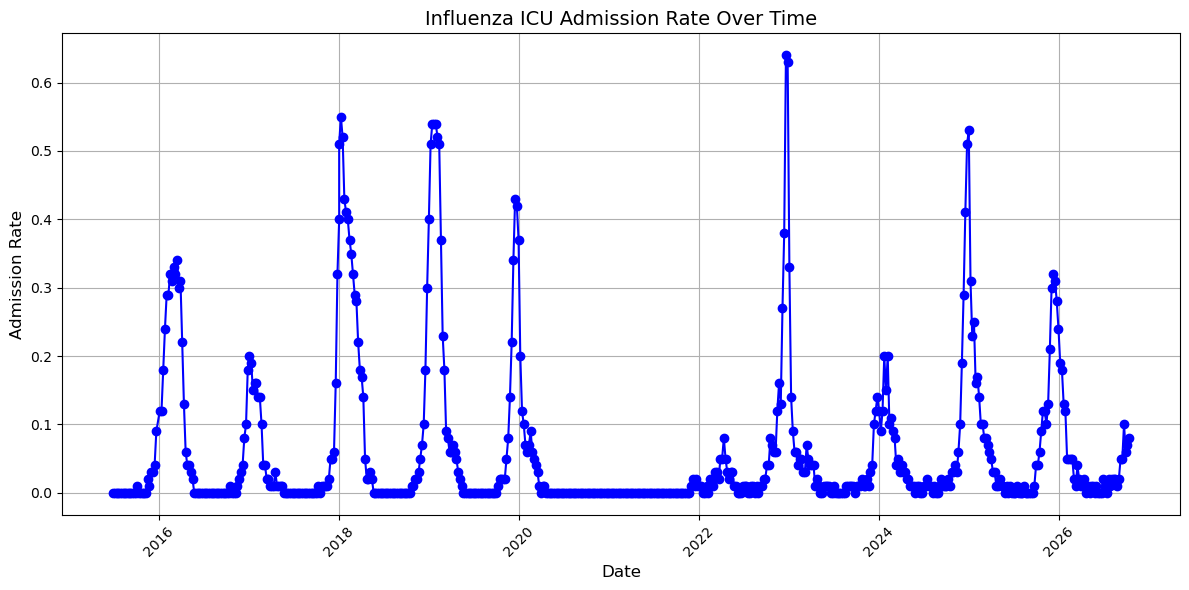

In [52]:
plot_df = df[(df["age"] == "all") & (df["sex"] == "all")]
plot_df["date"] = pd.to_datetime(plot_df["date"])
plt.figure(figsize=(12, 6))
plt.plot(plot_df["date"], plot_df["metric_value"], marker="o", linestyle="-", color="b")
plt.title("Influenza ICU Admission Rate Over Time", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Admission Rate", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [53]:
from IPython.display import clear_output
import ipywidgets as wdg
import pandas as pd
import matplotlib.pyplot as plt

In [54]:
%matplotlib inline
plt.rcParams['figure.dpi'] = 100

In [55]:
def access_api(button):
    apibutton.icon="check"
    apibutton.disabled=True

apibutton=wdg.Button(
    description='Refresh data',
    disabled=False,
    button_style='', # 'success', 'info', 'warning', 'danger' or ''
    tooltip='Click to download current Public Health England data',
    icon='download' # (FontAwesome names without the `fa-` prefix)
)

apibutton.on_click(access_api)
display(apibutton)

Button(description='Refresh data', icon='download', style=ButtonStyle(), tooltip='Click to download current Pu…